In [1]:
# Copyright (C) 2026  The Ohio State University

# This program is free software: you can redistribute it and/or modify
# it under the terms of the GNU General Public License as published by
# the Free Software Foundation, either version 3 of the License, or
# (at your option) any later version.
# This program is distributed in the hope that it will be useful,
# but WITHOUT ANY WARRANTY; without even the implied warranty of
# MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
# GNU General Public License for more details.

# You should have received a copy of the GNU General Public License
# along with this program.  If not, see <https://www.gnu.org/licenses/>.

# Results

Test-set results of the four shipped models (`Weights/`), computed from their per-particle predictions
(`Results/<model>/test_best/predictions.csv`, written by `Scripts/test_main.py`). The notebook needs neither a GPU nor
the dataset; only the gallery (section 4) needs the prepared test images (`guidance.md`).

- **Angle MAE**: mean |Predicted Angle − Annotated Angle| over the test particles; a missed particle counts as 90°.
- **Seed 614**: the shipped models. The check-ins reported the mean ± SD over training seeds 614–618 (no rotation: 614
  only); those per-seed values are in `Results/per_seed_test_angle_mae.csv`, and each can be rerun with
  `Scripts/train_main.py --seed <seed>`.
- **Human floor**: 2–3° Angle MAE, the error that annotation alone carries (two annotators, source publication).

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()  # the repo root, where this notebook sits
MODELS = {  # folder under Weights/ and Results/ -> label
    "baseline": "baseline model (3907 particles)",
    "4_per_bin_disk_rotation": "4 per bin, disk rotation (103)",
    "4_per_bin_ultralytics_rotation": "4 per bin, Ultralytics rotation (103)",
    "4_per_bin_no_rotation": "4 per bin, no rotation (103)",
}
COLORS = dict(zip(MODELS, ("black", "tab:blue", "tab:orange", "tab:green")))
HUMAN_FLOOR = (2, 3)  # degrees
MISS_DEG = 90.0  # Angle Error charged to a missed particle
RANGE = 10  # degrees of Annotated Angle per range

pred = {m: pd.read_csv(ROOT / "Results" / m / "test_best" / "predictions.csv") for m in MODELS}
per_seed = pd.read_csv(ROOT / "Results" / "per_seed_test_angle_mae.csv")


def abs_errors(df):
    """|Angle Error| per particle; a missed particle counts as 90°."""
    return df.angle_error.abs().where(df.detected, MISS_DEG)

## 1. Test Angle MAE

One row per model: the shipped run (seed 614) and, for reference, the mean ± SD over the training seeds listed.

In [3]:
rows = []
for m, label in MODELS.items():
    seeds = per_seed[per_seed.model == m]
    mae = seeds.test_angle_mae_deg
    rows.append({
        "model": label,
        "test particles": len(pred[m]),
        "detection rate": f"{pred[m].detected.mean():.1%}",
        "Angle MAE, seed 614 (°)": f"{abs_errors(pred[m]).mean():.2f}",
        "Angle MAE, mean ± SD over seeds (°)": f"{mae.mean():.2f} ± {mae.std():.2f}" if len(mae) > 1 else f"{mae.iloc[0]:.2f}",
        "training seeds": ", ".join(map(str, seeds.seed)),
    })
pd.DataFrame(rows).set_index("model")

,test particles,detection rate,"Angle MAE, seed 614 (°)","Angle MAE, mean ± SD over seeds (°)",training seeds
model,,,,,
baseline model (3907 particles),489,100.0%,2.69,2.65 ± 0.09,"614, 615, 616, 617, 618"
"4 per bin, disk rotation (103)",489,100.0%,3.08,3.04 ± 0.11,"614, 615, 616, 617, 618"
"4 per bin, Ultralytics rotation (103)",489,100.0%,3.45,3.34 ± 0.10,"614, 615, 616, 617, 618"
"4 per bin, no rotation (103)",489,99.8%,11.72,11.72,614


## 2. Validation Angle MAE per epoch (seed 614)

From each model's `results.csv` in `Weights/`. The validation Angle MAE picks the checkpoint (dot = best epoch, saved
as `best.pt`), and training stops 50 epochs after it.

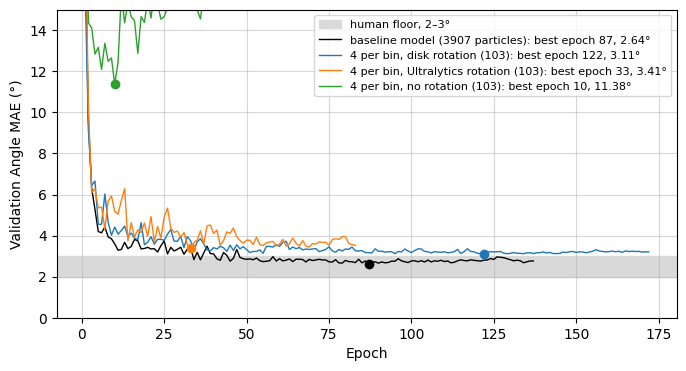

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.axhspan(*HUMAN_FLOOR, color="0.85", label="human floor, 2–3°")
for m, label in MODELS.items():
    curve = pd.read_csv(ROOT / "Weights" / m / "results.csv")
    best = curve.loc[curve["metrics/angle_MAE"].idxmin()]
    ax.plot(curve.epoch, curve["metrics/angle_MAE"], color=COLORS[m], linewidth=1,
            label=f"{label}: best epoch {best.epoch:.0f}, {best['metrics/angle_MAE']:.2f}°")
    ax.scatter(best.epoch, best["metrics/angle_MAE"], color=COLORS[m], zorder=3)
ax.set(xlabel="Epoch", ylabel="Validation Angle MAE (°)", ylim=(0, 15))
ax.legend(fontsize=8)
ax.grid(alpha=0.5)
plt.show()

## 3. Predicted vs Annotated Angle, and Angle MAE per 10° range (seed 614)

Left: one dot per test particle for the baseline model and the 4-per-bin disk-rotation model; dashed line = perfect
agreement. Right: Angle MAE per 10° range of the Annotated Angle for the baseline and the two rotation models; the
number under each range is its count of test particles.

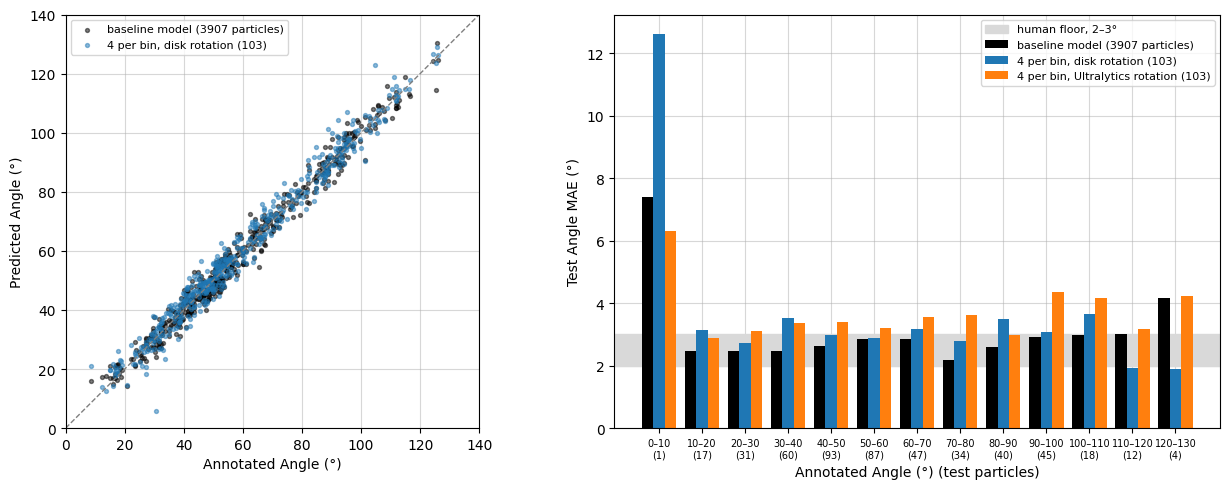

In [5]:
fig, (ax_s, ax_b) = plt.subplots(1, 2, figsize=(13, 5))
lim = (0, 140)
ax_s.plot(lim, lim, color="0.5", linestyle="--", linewidth=1)
for m in ("baseline", "4_per_bin_disk_rotation"):
    df = pred[m][pred[m].detected]
    ax_s.scatter(df.annotated_angle, df.predicted_angle, s=8, alpha=0.5, color=COLORS[m], label=MODELS[m])
ax_s.set(xlabel="Annotated Angle (°)", ylabel="Predicted Angle (°)", xlim=lim, ylim=lim, aspect="equal")
ax_s.legend(fontsize=8, loc="upper left")

shown = ("baseline", "4_per_bin_disk_rotation", "4_per_bin_ultralytics_rotation")
ranges = (pred["baseline"].annotated_angle // RANGE * RANGE).astype(int)
starts = sorted(ranges.unique())
width = 0.8 * RANGE / len(shown)
ax_b.axhspan(*HUMAN_FLOOR, color="0.85", label="human floor, 2–3°")
for i, m in enumerate(shown):
    mae = abs_errors(pred[m]).groupby((pred[m].annotated_angle // RANGE * RANGE).astype(int)).mean()
    ax_b.bar(np.array(starts) + 0.1 * RANGE + (i + 0.5) * width, mae.reindex(starts), width=width, color=COLORS[m],
             label=MODELS[m])
counts = ranges.value_counts()
ax_b.set_xticks(np.array(starts) + RANGE / 2, [f"{s}–{s + RANGE}\n({counts[s]})" for s in starts], fontsize=7)
ax_b.set(xlabel="Annotated Angle (°) (test particles)", ylabel="Test Angle MAE (°)")
ax_b.legend(fontsize=8)
for ax in (ax_s, ax_b):
    ax.grid(alpha=0.5)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 4. Gallery: typical and worst test particles of the 4-per-bin disk-rotation model (seed 614)

Needs the prepared test images in `Dataset/Primary_224px/test/images` (`guidance.md`); skipped otherwise.
Top: for 4 target angles, the test particle nearest to it among those with |Angle Error| < 5°. Bottom: the 4 particles
with the largest |Angle Error|. Green = annotated, red = predicted keypoints (tip A, vertex, tip B); titles: Annotated
→ Predicted Angle.

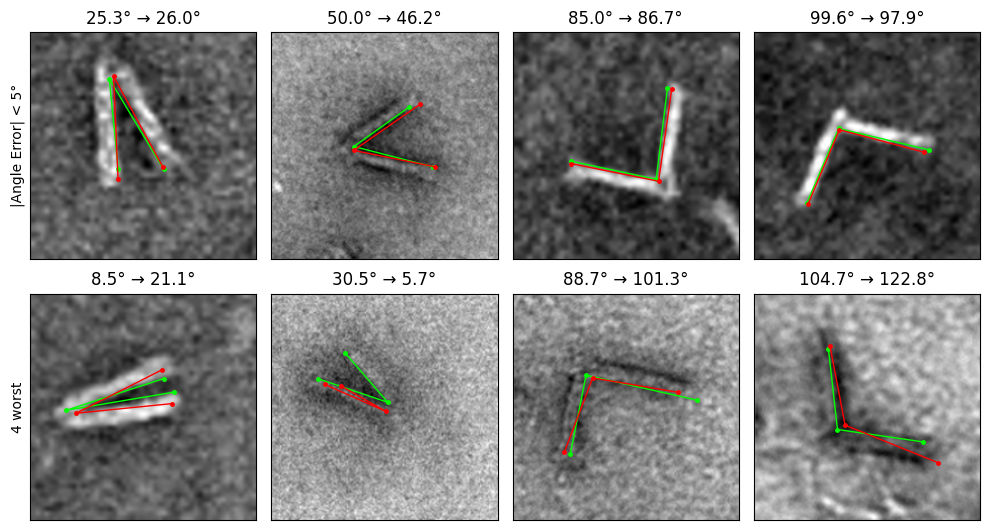

In [6]:
import cv2

image_dir = ROOT / "Dataset" / "Primary_224px" / "test" / "images"
df = pred["4_per_bin_disk_rotation"]
if not image_dir.exists():
    print(f"Skipped: {image_dir} not found (see guidance.md)")
else:
    good = df[df.detected & (df.angle_error.abs() < 5)]
    typical = pd.concat([good.loc[[(good.annotated_angle - t).abs().idxmin()]] for t in (25, 50, 85, 100)])
    worst = df.loc[abs_errors(df).nlargest(4).index].sort_values("annotated_angle")
    fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
    for row_axes, rows, label in ((axes[0], typical, "|Angle Error| < 5°"), (axes[1], worst, "4 worst")):
        for ax, (_, r) in zip(row_axes, rows.iterrows()):
            ax.imshow(cv2.imread(str(image_dir / r.image), cv2.IMREAD_GRAYSCALE), cmap="gray")
            for prefix, color in (("annotated", "lime"), ("predicted", "red")):
                x = [r[f"{prefix}_{k}_x_px"] - 0.5 for k in ("tip_a", "vertex", "tip_b")]  # pixel centers at integers
                y = [r[f"{prefix}_{k}_y_px"] - 0.5 for k in ("tip_a", "vertex", "tip_b")]
                ax.plot(x, y, color=color, linewidth=1, marker="o", markersize=2.5)
            ax.set(xticks=[], yticks=[], title=f"{r.annotated_angle:.1f}° → {r.predicted_angle:.1f}°")
        row_axes[0].set_ylabel(label)
    plt.tight_layout()
    plt.show()